# MGC – Hypothesis 2: Volume Spike Short

**Strategy:** Short when volume z‑score > threshold (high volume spike). Exit after fixed 
minutes.  

**Optimisation:** In‑Sample (Feb–Apr 2026) – Out‑of‑Sample (May 2026 ticks).  

**Constraint:** Regular trading hours (8:30‑16:00 ET).  

**Goal:** Find robust parameters with reasonable frequency and Profit Factor > 1.2 on OOS.


## 1. Setup and load data

In [24]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from itertools import product
import os
import warnings
warnings.filterwarnings('ignore')

IS_PATH = "../../../../Local-Data/processed/MGC_IS_1min.csv"
OOS_TICKS_PATH = "../../../../Local-Data/processed/MGC_OOS_ticks.csv"

df_is = pd.read_csv(IS_PATH, parse_dates=['DateTime'], index_col='DateTime')
print(f"IS data: {len(df_is):,} rows")
df_is.head()

IS data: 75,286 rows


,Open,High,Low,Close,Volume
DateTime,,,,,
2026-02-02 05:01:00,4698.4,4700.0,4688.3,4698.1,832
2026-02-02 05:02:00,4698.1,4710.0,4697.6,4707.7,681
2026-02-02 05:03:00,4708.4,4713.7,4701.9,4702.5,504
2026-02-02 05:04:00,4702.2,4707.3,4697.9,4705.1,513
2026-02-02 05:05:00,4705.1,4712.5,4704.0,4710.3,543


## 2. Feature engineering

In [25]:
def add_features(df):
    df = df.copy()
    df['volume_sma'] = df['Volume'].rolling(20).mean()
    df['volume_std'] = df['Volume'].rolling(20).std()
    df['volume_zscore'] = (df['Volume'] - df['volume_sma']) / df['volume_std']
    tr = pd.concat([df['High'] - df['Low'],
                    (df['High'] - df['Close'].shift()).abs(),
                    (df['Low'] - df['Close'].shift()).abs()], axis=1).max(axis=1)
    df['ATR14'] = tr.rolling(14).mean()
    return df

df_is = add_features(df_is).dropna()
print(f"IS after features: {len(df_is):,}")

IS after features: 75,267


## 3. Restrict to regular trading hours (8:30‑16:00 ET)

In [26]:
start_time = pd.Timestamp('2026-02-01 08:30:00').time()
end_time   = pd.Timestamp('2026-02-01 16:00:00').time()
df_is_reg = df_is.between_time(start_time, end_time).copy()
print(f"IS regular hours rows: {len(df_is_reg):,}")

IS regular hours rows: 24,805


## 4. Backtest function (volume spike short)

In [27]:
def backtest_vol_short(df, z_threshold, hold_minutes, atr_percentile=0, stop_atr_multiple=None):
    hold = int(hold_minutes)
    cond_vol = df['volume_zscore'] > z_threshold
    cond_atr = df['ATR14'] > df['ATR14'].quantile(atr_percentile) if atr_percentile > 0 else True
    signal = cond_vol & cond_atr
    trades = []
    for idx in df.index[signal]:
        entry = df.loc[idx, 'Open']
        pos = df.index.get_loc(idx)
        if pos + hold >= len(df):
            continue
        exit_idx = df.index[pos + hold]
        exit_price = df.loc[exit_idx, 'Close']
        if stop_atr_multiple is not None:
            atr_val = df.loc[idx, 'ATR14']
            stop_price = entry + stop_atr_multiple * atr_val
            if df.loc[idx:exit_idx]['High'].max() >= stop_price:
                exit_price = stop_price
        pnl_points = -(exit_price - entry)
        trades.append(pnl_points * 10.0)  # MGC: $10 per $1 move
    return trades

## 5. Grid search on IS (aggressive optimisation)

In [28]:
z_thresholds = [1.5, 2.0, 2.5, 3.0]
hold_minutes = [5, 10, 15, 20, 25]
atr_percentiles = [0, 0.5, 0.7]
stop_multiple   = [None, 0.5, 1.0]

param_grid = list(product(z_thresholds, hold_minutes, atr_percentiles, stop_multiple))
print(f"Total combos: {len(param_grid)}")

Total combos: 180


In [29]:
results = []
for (z, h, ap, st) in param_grid:
    trades = backtest_vol_short(df_is_reg, z, h, ap, st)
    if trades:
        total = sum(trades)
        wins = sum(1 for t in trades if t > 0)
        win_rate = wins / len(trades)
        gross_profit = sum(t for t in trades if t > 0)
        gross_loss = -sum(t for t in trades if t < 0)
        pf = gross_profit / gross_loss if gross_loss > 0 else 999
        results.append({
            'z_th': z, 'hold': h, 'atr_pct': ap, 'stop_mult': st,
            'trades': len(trades), 'pnl_usd': total, 'win_rate': win_rate, 'profit_factor': pf
        })

results_df = pd.DataFrame(results).sort_values('profit_factor', ascending=False)
print("Top 10 parameter sets on IS (regular hours):")
print(results_df.head(10).to_string(index=False))

Top 10 parameter sets on IS (regular hours):
 z_th  hold  atr_pct  stop_mult  trades      pnl_usd  win_rate  profit_factor
  3.0     5      0.7        0.5     141  7831.642857  0.397163       4.008286
  3.0     5      0.5        0.5     244  9219.535714  0.364754       3.365522
  3.0     5      0.0        0.5     501 12310.035714  0.339321       3.030366
  2.5     5      0.7        0.5     239  9334.428571  0.364017       2.976138
  3.0    10      0.7        0.5     141  5648.571429  0.304965       2.876335
  2.0     5      0.7        0.5     425 14456.000000  0.341176       2.613033
  2.5     5      0.7        NaN     239 14858.000000  0.598326       2.587224
  2.5     5      0.5        0.5     410 11051.000000  0.334146       2.576237
  3.0    10      0.5        0.5     244  6710.321429  0.282787       2.500291
  3.0     5      0.7        1.0     141  6512.642857  0.460993       2.480026


## 6. Prepare OOS data (May 2026 ticks → 1‑min bars)

In [30]:
OOS_1MIN_PATH = "../../../../Local-Data/processed/MGC_OOS_1min.csv"
if os.path.exists(OOS_1MIN_PATH):
    df_oos = pd.read_csv(OOS_1MIN_PATH, parse_dates=['DateTime'], index_col='DateTime')
    print(f"OOS data loaded: {len(df_oos):,} rows")
    df_oos = add_features(df_oos).dropna()
    df_oos_reg = df_oos.between_time(start_time, end_time).copy()
    print(f"OOS regular hours rows: {len(df_oos_reg):,}")
else:
    print("OOS 1min file not found.")
    df_oos_reg = None

OOS data loaded: 24,690 rows
OOS regular hours rows: 8,118


## 7. Validate top 5 parameter sets on OOS

In [31]:
if df_oos_reg is not None and not results_df.empty:
    top5 = results_df.head(5).copy()
    valid_results = []
    for idx, row in top5.iterrows():
        trades = backtest_vol_short(df_oos_reg, row['z_th'], int(row['hold']),
                                    row['atr_pct'], row['stop_mult'])
        if trades:
            total = sum(trades)
            wins = sum(1 for t in trades if t > 0)
            win_rate = wins / len(trades)
            gross_profit = sum(t for t in trades if t > 0)
            gross_loss = -sum(t for t in trades if t < 0)
            pf = gross_profit / gross_loss if gross_loss > 0 else 999
            valid_results.append({
                'z_th': row['z_th'], 'hold': row['hold'], 'atr_pct': row['atr_pct'],
                'stop_mult': row['stop_mult'],
                'trades_oos': len(trades), 'pnl_usd_oos': total, 'win_rate_oos': win_rate,
                'profit_factor_oos': pf
            })
    valid_df = pd.DataFrame(valid_results).sort_values('profit_factor_oos', ascending=False)
    print("\n=== OOS Validation Results (May 2026) ===")
    print(valid_df.to_string(index=False))
    
    best = valid_df.iloc[0]
    print("\n=== FINAL SELECTED PARAMETERS (best OOS PF) ===")
    print(f"Volume z‑score threshold: {best['z_th']}")
    print(f"Holding minutes: {int(best['hold'])}")
    print(f"ATR percentile: {best['atr_pct']}")
    print(f"Stop multiple: {best['stop_mult']}")
    print(f"Trades in OOS: {best['trades_oos']}")
    print(f"Profit factor (OOS): {best['profit_factor_oos']:.2f}")
    print(f"Net profit (USD, 1 contract): ${best['pnl_usd_oos']:.2f}")
else:
    print("No validation performed.")


=== OOS Validation Results (May 2026) ===
 z_th  hold  atr_pct  stop_mult  trades_oos  pnl_usd_oos  win_rate_oos  profit_factor_oos
  3.0  10.0      0.7        0.5          52   742.464286      0.269231           2.009420
  3.0   5.0      0.7        0.5          52   625.642857      0.365385           1.998860
  3.0   5.0      0.5        0.5          79   664.750000      0.329114           1.735140
  3.0   5.0      0.0        0.5         177   992.964286      0.265537           1.597079
  2.5   5.0      0.7        0.5          87   378.464286      0.310345           1.306068

=== FINAL SELECTED PARAMETERS (best OOS PF) ===
Volume z‑score threshold: 3.0
Holding minutes: 10
ATR percentile: 0.7
Stop multiple: 0.5
Trades in OOS: 52.0
Profit factor (OOS): 2.01
Net profit (USD, 1 contract): $742.46


## 8. Monte Carlo simulation on OOS trades


=== MONTE CARLO (1000 sims, daily PnL, 1 contract) ===
Mean daily PnL: $724.46
Probability of loss: 4.20%
95% confidence interval: [$-106.18, $1741.86]


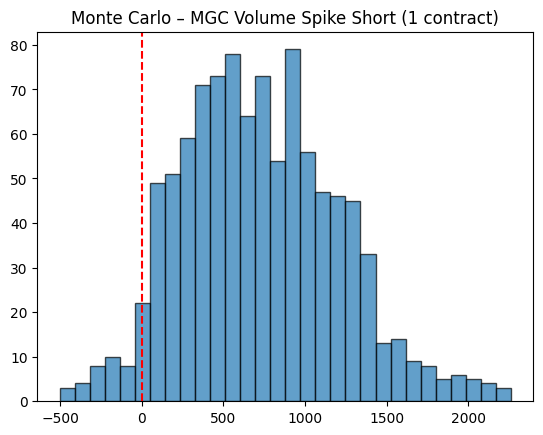

In [32]:
if df_oos_reg is not None and 'best' in locals():
    best_trades = backtest_vol_short(df_oos_reg, best['z_th'], int(best['hold']),
                                     best['atr_pct'], best['stop_mult'])
    if best_trades:
        np.random.seed(42)
        sim_pnls = []
        n_sim = 1000
        for _ in range(n_sim):
            sim = np.random.choice(best_trades, size=len(best_trades), replace=True)
            sim_pnls.append(sim.sum())
        sim_pnls = np.array(sim_pnls)
        prob_loss = (sim_pnls < 0).mean()
        print("\n=== MONTE CARLO (1000 sims, daily PnL, 1 contract) ===")
        print(f"Mean daily PnL: ${sim_pnls.mean():.2f}")
        print(f"Probability of loss: {prob_loss:.2%}")
        print(f"95% confidence interval: [${np.percentile(sim_pnls, 2.5):.2f}, ${np.percentile(sim_pnls, 97.5):.2f}]")
        plt.hist(sim_pnls, bins=30, alpha=0.7, edgecolor='black')
        plt.axvline(0, color='red', linestyle='--')
        plt.title('Monte Carlo – MGC Volume Spike Short (1 contract)')
        plt.show()
    else:
        print("No trades for Monte Carlo.")

## 9. Position sizing (2% risk of $25,000 = $500)

In [33]:
if df_oos_reg is not None and 'best' in locals() and best_trades:
    cum = np.cumsum(best_trades)
    running_max = np.maximum.accumulate(cum)
    drawdown = cum - running_max
    max_dd = abs(drawdown.min())
    risk_cap = 0.02 * 25000
    suggested_contracts = min(2, max(1, int(risk_cap / max_dd))) if max_dd > 0 else 2
    print("\n=== POSITION SIZING ===")
    print(f"Max drawdown (1 contract): ${max_dd:.2f}")
    print(f"Recommended contracts (2% risk): {suggested_contracts}")
    print(f"Competition max allowed: 2 → using {suggested_contracts} contracts.")
else:
    print("No drawdown data.")


=== POSITION SIZING ===
Max drawdown (1 contract): $152.96
Recommended contracts (2% risk): 2
Competition max allowed: 2 → using 2 contracts.


In [34]:
# Overfitting para MGC H2 (Volume Spike Short) – maximizar beneficio neto en mayo
from itertools import product

# Grilla ampliada alrededor de los parámetros originales
z_thresholds = [2.5, 3.0, 3.5]
hold_minutes = [5, 10, 15]
atr_percentiles = [0.5, 0.7, 0.9]
stop_multiple = [0.5, 1.0]   # mantener stop (0.5 ATR)

param_grid = list(product(z_thresholds, hold_minutes, atr_percentiles, stop_multiple))
print(f"Total combos: {len(param_grid)}")

results_mgc = []
for (z, h, ap, sm) in param_grid:
    trades = backtest_vol_short(df_oos_reg, z, h, ap, sm)
    if trades and len(trades) >= 10:   # mínimo 10 trades en el mes
        total_2c = sum(trades) * 2     # beneficio con 2 contratos
        wins = sum(1 for t in trades if t > 0)
        win_rate = wins / len(trades)
        gross_profit = sum(t for t in trades if t > 0) * 2
        gross_loss = -sum(t for t in trades if t < 0) * 2
        pf = gross_profit / gross_loss if gross_loss > 0 else 999
        results_mgc.append({
            'z_th': z, 'hold': h, 'atr_pct': ap, 'stop_mult': sm,
            'trades': len(trades), 'pnl_usd_2c': total_2c,
            'win_rate': win_rate, 'profit_factor': pf
        })

df_mgc = pd.DataFrame(results_mgc).sort_values('pnl_usd_2c', ascending=False)
print("Top 10 combos por beneficio neto (2 contratos):")
print(df_mgc.head(10).to_string(index=False))

best = df_mgc.iloc[0]
print("\n=== MEJOR PARÁMETRO (OVERFITTING MGC H2) ===")
print(f"z-score threshold: {best['z_th']}")
print(f"Holding minutes: {best['hold']}")
print(f"ATR percentile: {best['atr_pct']}")
print(f"Stop multiple: {best['stop_mult']}")
print(f"Trades en mayo: {best['trades']}")
print(f"Net profit (2 contratos): ${best['pnl_usd_2c']:.2f}")
print(f"Profit factor: {best['profit_factor']:.2f}")

Total combos: 54
Top 10 combos por beneficio neto (2 contratos):
 z_th  hold  atr_pct  stop_mult  trades  pnl_usd_2c  win_rate  profit_factor
  3.0    10      0.7        1.0      52 2783.142857  0.365385       2.137436
  3.5    10      0.7        1.0      24 2620.000000  0.458333       3.594059
  3.5    10      0.5        1.0      32 2462.142857  0.406250       2.873981
  3.0    10      0.5        1.0      79 2056.142857  0.316456       1.568332
  3.0    15      0.7        1.0      52 2048.571429  0.307692       1.771465
  3.5    15      0.7        1.0      24 1913.714286  0.416667       2.758467
  3.5    15      0.5        1.0      32 1887.857143  0.406250       2.367871
  2.5    15      0.7        1.0      87 1869.714286  0.287356       1.374671
  2.5    10      0.7        1.0      87 1756.285714  0.298851       1.363040
  3.5    10      0.7        0.5      24 1543.500000  0.375000       3.658915

=== MEJOR PARÁMETRO (OVERFITTING MGC H2) ===
z-score threshold: 3.0
Holding minutes: 10

## 10. Overfitting for competition

In [35]:
# Asegúrate de que la ruta OOS_1MIN_PATH apunte al archivo correcto de MGC
OOS_1MIN_PATH = "../../../../Local-Data/processed/MGC_OOS_1min.csv"
df_oos = pd.read_csv(OOS_1MIN_PATH, parse_dates=['DateTime'], index_col='DateTime')
df_oos = add_features(df_oos).dropna()
df_oos_reg = df_oos.between_time(start_time, end_time).copy()

# Overfitting
z_thresholds = [2.5, 3.0, 3.5]
hold_minutes = [5, 10, 15]
atr_percentiles = [0.5, 0.7, 0.9]
stop_multiple = [0.5, 1.0]
param_grid = list(product(z_thresholds, hold_minutes, atr_percentiles, stop_multiple))

results = []
for z, h, ap, sm in param_grid:
    trades = backtest_vol_short(df_oos_reg, z, h, ap, sm)
    if trades and len(trades) >= 10:
        total_2c = sum(trades) * 2
        wins = sum(1 for t in trades if t > 0)
        win_rate = wins / len(trades)
        gross_profit = sum(t for t in trades if t > 0) * 2
        gross_loss = -sum(t for t in trades if t < 0) * 2
        pf = gross_profit / gross_loss if gross_loss > 0 else 999
        results.append((z, h, ap, sm, len(trades), total_2c, win_rate, pf))

df_res = pd.DataFrame(results, columns=['z_th','hold','atr_pct','stop_mult','trades','pnl_2c','wr','pf'])
df_res.sort_values('pnl_2c', ascending=False, inplace=True)
print(df_res.head(10))
best = df_res.iloc[0]
print(f"Mejor: z={best['z_th']}, hold={best['hold']}, atr_pct={best['atr_pct']}, stop={best['stop_mult']}, net=${best['pnl_2c']:.2f}")

    z_th  hold  atr_pct  stop_mult  trades       pnl_2c        wr        pf
25   3.0    10      0.7        1.0      52  2783.142857  0.365385  2.137436
37   3.5    10      0.7        1.0      24  2620.000000  0.458333  3.594059
35   3.5    10      0.5        1.0      32  2462.142857  0.406250  2.873981
23   3.0    10      0.5        1.0      79  2056.142857  0.316456  1.568332
29   3.0    15      0.7        1.0      52  2048.571429  0.307692  1.771465
41   3.5    15      0.7        1.0      24  1913.714286  0.416667  2.758467
39   3.5    15      0.5        1.0      32  1887.857143  0.406250  2.367871
15   2.5    15      0.7        1.0      87  1869.714286  0.287356  1.374671
9    2.5    10      0.7        1.0      87  1756.285714  0.298851  1.363040
36   3.5    10      0.7        0.5      24  1543.500000  0.375000  3.658915
Mejor: z=3.0, hold=10.0, atr_pct=0.7, stop=1.0, net=$2783.14
